# **CS 554 - Assignment 1: Prompting, Fine-Tuning and Retrieval with Gemma-3-1B (100 pts)**

In this assignment, you will work with one open-source model, Gemma-3-1B, in three ways: write prompts for it, fine-tune
it with LoRA and QLoRA, and connect it to a BM25 retriever. At the end you will combine fine-tuning and retrieval and
compare the four resulting systems. One idea runs through the whole assignment: a language model is $y = f_\theta(x)$.
Prompting and retrieval change the input **x**; fine-tuning changes the parameters **θ**. Each task changes one of the
two and looks at how the output **y** responds.

| Task | Code | Discussion | Total |
|---|---:|---:|---:|
| 1. Load Gemma and compare three prompts | 12 | 3 | 15 |
| 2. Fine-tune with LoRA and QLoRA | 26 | 14 | 40 |
| 3. Retrieve with BM25 | 15 | 10 | 25 |
| 4. Combine fine-tuning and retrieval | 7 | 13 | 20 |
| **Total** | **60** | **40** | **100** |

### **Grading**

Complete every `TODO`. The training and evaluation settings are fixed; please do not change them. Your grade does not
depend on how high your accuracy is: correct code, a complete run and a basic reading of your results earn 80 points.
The remaining 20 points are for actually looking at your own run records and using them to support what you claim.

There are six discussion questions. Each one must cite your own run: the row id, the model's full reply, all accepted
gold answers for that question, and the context when it matters. The notebook contains a few *viewer* cells for this.
They do not run the model again; they print the predictions that were already generated, for the rows whose ids you
enter. Expand the folded code, set the ids you want to inspect, and re-run the cell.

Sometimes your run will not contain the kind of example a question asks for, for instance no question at all got worse
after fine-tuning. That costs nothing. State how many candidates there were and how you searched, inspect another row of
the same group instead, and keep your conclusion accordingly narrow.

### **GPU Choice**

Use Google Colab with the free **T4** GPU. The whole assignment was designed and tested on a T4 and needs about one hour
of GPU time; the training settings (fp16, batch size) assume it. Please do not use TPUs or other GPU types: memory and
precision behave differently there, and we may not be able to help with problems on other hardware. Colab Pro is free for
students but is not needed for this assignment.

### **Google Colab Tips**

- If the session is idle for a while, **the runtime disconnects** and unsaved progress is lost. The assignment is meant
  to be done in one session, so schedule a slot in which you can run it from top to bottom without long breaks.
- After Task 2 there is an optional backup cell that downloads your trained adapter. If the runtime resets later, the
  recovery cell at the start of Task 3 loads it back, so you do not have to train again.
- The starter code that loads the data and the model is included. The first assignments of this course all work with
  Gemma-3-1B.

### **Submission**

Submit this notebook (`.ipynb`) on Canvas with all outputs and answers included; no other files are needed. Make sure it
runs end-to-end without errors. Follow the course AI policy, and be ready to explain your own notebook in section.

### **Enabling the GPU in Colab**

- Go to the top menu: Runtime → Change runtime type.
- Under Hardware accelerator, select **T4 GPU**.

Then run the provided cell to check that a GPU is available. Run the install cell **once**, then Runtime →
**Restart session**, and continue from *Prepare model access* below. Running the install cell twice causes package
conflicts.

In [1]:
#@title Check GPU (provided)

import torch
print("CUDA available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "select a GPU runtime")

CUDA available: True | Tesla T4


In [2]:
#@title Install ONCE, then Restart session (provided)

# run ONCE, then Runtime -> Restart session
! pip -q install -U "pyarrow" "datasets==5.0.1" "transformers==5.16.1" "peft==0.20.0" "accelerate" "bitsandbytes==0.50.2" "huggingface_hub" "rank_bm25"
! pip -q uninstall -y torchao
print("Install finished -> Runtime -> Restart session")

Install finished -> Runtime -> Restart session


### **Prepare Model Access**

Gemma-3-1B is a gated model: before you can download it, you must accept its license and authenticate with your
Hugging Face account. Please follow these steps carefully:

1. Open https://huggingface.co/google/gemma-3-1b-it and click "Acknowledge License". You need a Hugging Face account
   with a verified e-mail address.
2. In your account settings, go to "Access Tokens" and create a token of type **Read**. Copy it right away and keep it
   somewhere safe; you cannot see it again after leaving the page.
3. In Colab, open the "Secrets" panel (the key icon on the left), add a secret named `HF_TOKEN` with the token as its
   value, and enable Notebook access. The cell below reads it with `userdata.get("HF_TOKEN")` and logs in.
4. Never paste the token into a cell: you will submit this notebook.

If you work on your own machine instead, put a line `HF_TOKEN=hf_...` into a `.env` file and read it with `os.getenv`.
If you are not familiar with that flow, we recommend Colab.

Common errors: a 401 or 403 means the license was not accepted, the token is invalid, or the secret is not named
`HF_TOKEN`. An import error after installing means the session was not restarted.

In [3]:
#@title Login and imports — continue here after restart (provided)

%env PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True

from google.colab import userdata
from huggingface_hub import login
login(userdata.get("HF_TOKEN")); print("Hugging Face login OK")

import os, re, json, random, time, string, gc, shutil, statistics as st
from collections import Counter, defaultdict
import numpy as np, pandas as pd, torch
import transformers, peft, bitsandbytes, datasets

MODEL_ID, SEED = "google/gemma-3-1b-it", 42
random.seed(SEED); torch.manual_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__, "| bitsandbytes", bitsandbytes.__version__, "| datasets", datasets.__version__)

env: PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
Hugging Face login OK
GPU: Tesla T4 | torch 2.11.0+cu130 | transformers 5.16.1 | peft 0.20.0 | bitsandbytes 0.50.2 | datasets 5.0.1


## **Task 1: Load Gemma and Compare Three Prompts (15 pts)**

In this task, you will get the model running and then look at how its answer to the same question changes with the form
of the input.

Gemma-3-1B-it is a chat model: it uses a chat template to tell the user's turn from its own reply, and `load_model` and
`run_inference` must use that template. Then complete `build_prompt` with an instruction of your own that asks for a
short answer. The three modes are **direct** (the question only), **context** (passage + question) and
**prompt+context** (your instruction + passage + question). Run each mode on the three supplied examples, nine replies
in total. This task uses sampling, so repeated runs can give different replies; that is expected.

The data is prepared for you: 1,000 training rows from SQuAD 2.0, and `EVAL` with 100 rows, 50 whose passage contains
the answer and 50 whose passage does not. Some of the no-answer rows were made by pairing a question with another
paragraph of the same article. Each row's `answers` holds every accepted gold answer; `answer` is only the first one,
and scoring uses all of them.

###**Grading Breakdown:**
1. `load_model` (4 pts)
2. `run_inference` (4 pts)
3. Your prompt template and the nine replies (4 pts)
4. Discussion (3 pts)

Refer to the following official guides:
1. [Loading and generation](https://huggingface.co/docs/transformers/en/quicktour#pretrained-models)
2. [Chat templates](https://huggingface.co/docs/transformers/chat_templating#using-applychattemplate)

In [4]:
# 1.1  Load the model (4 pts)

from transformers import AutoTokenizer, AutoModelForCausalLM

def load_model(model_name):
    """
    Args:
        model_name: Hugging Face model id, e.g. "google/gemma-3-1b-it"
    Returns:
        tokenizer, model
    """
    ## Step 1: Load the tokenizer (turns text into token numbers and back)
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    ## Step 2: Load the model in 16-bit, on the GPU, with standard attention
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        dtype="auto",
        device_map="auto",
        attn_implementation="eager",
    )
    return tokenizer, model

tokenizer, model = load_model(MODEL_ID)
print(type(model).__name__, "|", model.device, "|", model.dtype)

# provided settings used by every later cell
tokenizer.padding_side = "left"
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
BOS_ID, END_OF_TURN_ID = tokenizer.bos_token_id, tokenizer.convert_tokens_to_ids("<end_of_turn>")     # a Gemma turn ends with <end_of_turn>

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

Gemma3ForCausalLM | cuda:0 | torch.bfloat16


In [ ]:
# 1.2  Generate a reply (4 pts)

def run_inference(model, prompt, max_new_tokens=50):
    """
    Args:
        model: the loaded Gemma model
        prompt: the text of one user message
        max_new_tokens: how many new tokens to generate at most
    Returns:
        generated_text: the assistant's reply as a string (only the new text, not the prompt)
    """
    ## Step 1: Put the prompt into one user message
    messages = [{"role": "user", "content": prompt}]

    ## Step 2: Apply Gemma's chat template and move it to the GPU
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    ## Step 3: Generate the reply
    outputs = model.generate(**inputs, max_new_tokens=max_new_tokens)

    ## Step 4: Keep only the new tokens and turn them back into text
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    generated_text = tokenizer.decode(new_tokens, skip_special_tokens=True)
    return generated_text

my_prompt = "What is traffic congestion? Answer in one sentence."
if not my_prompt.strip(): raise ValueError("Write your own prompt in my_prompt before running this cell.")
print(run_inference(model, my_prompt))

Traffic congestion is a state of excessive traffic flow that slows down vehicles and increases travel times due to a combination of factors.


In [5]:
#@title Prepare the SQuAD rows (provided)

# provided - run as is: builds train_rows, val_rows and EVAL
from datasets import load_dataset, Dataset
NO_ANSWER = "NOT IN CONTEXT"
sq = load_dataset("rajpurkar/squad_v2")

def build_pools(ds):
    answerable, unanswerable = [], []
    for r in ds:
        ctx, q, texts = r["context"].strip(), r["question"].strip(), [t.strip() for t in r["answers"]["text"] if t.strip()]
        if texts and len(texts[0].split()) <= 8:
            answerable.append({"kind": "answerable", "title": r["title"], "context": ctx, "question": q, "answer": texts[0], "answers": texts})
        elif not texts:
            unanswerable.append({"kind": "no answer", "title": r["title"], "context": ctx, "question": q, "answer": NO_ANSWER, "answers": [NO_ANSWER]})
    return answerable, unanswerable

train_ans, train_un = build_pools(sq["train"]); val_ans, val_un = build_pools(sq["validation"])
rng = random.Random(SEED)
for pool in (train_ans, train_un, val_ans, val_un): rng.shuffle(pool)
def by_title(pool):
    idx = defaultdict(list)
    for p in pool: idx[p["title"]].append(p)
    return idx
train_by_title, val_by_title = by_title(train_ans), by_title(val_ans)

def wrong_context_row(src, idx, pool):      # src's question with another paragraph (same article if possible) that lacks its answer
    usable = lambda o: o["context"] != src["context"] and not any(a.lower() in o["context"].lower() for a in src["answers"])
    cands = [p for p in idx.get(src["title"], []) if usable(p)] or [p for p in rng.sample(pool, 40) if p["title"] != src["title"] and usable(p)]
    if not cands: return None
    o = cands[rng.randrange(len(cands))]
    return {"kind": "no answer", "title": o["title"], "context": o["context"], "question": src["question"], "answer": NO_ANSWER, "answers": [NO_ANSWER]}
def wrong_rows(srcs, idx, pool, n): return [w for w in (wrong_context_row(r, idx, pool) for r in srcs) if w][:n]

train_rows = train_ans[:700] + train_un[:200] + wrong_rows(train_ans[700:900], train_by_title, train_ans, 100); rng.shuffle(train_rows)
val_rows = val_ans[:25] + val_un[:12] + wrong_rows(val_ans[25:75], val_by_title, val_ans, 13); rng.shuffle(val_rows)      # validation loss only
EVAL = val_ans[100:150] + val_un[50:75] + wrong_rows(val_ans[200:300], val_by_title, val_ans, 25)                          # 50 answerable, then 50 no answer
print("train:", dict(Counter(r["kind"] for r in train_rows)), "| EVAL:", dict(Counter(r["kind"] for r in EVAL)))
for r in (train_rows[0], next(x for x in train_rows if x["kind"] == "no answer")):
    print(f"\n[{r['kind']}] Q: {r['question']}\n  target (training/scoring only): {r['answer']}\n  passage: {r['context'][:120]}...")

train: {'answerable': 700, 'no answer': 300} | EVAL: {'answerable': 50, 'no answer': 50}

[answerable] Q: What kind of institution is KU's School of Business?
  target (training/scoring only): public
  passage: The University of Kansas School of Business is a public business school located on the main campus of the University of ...

[no answer] Q: What city did Boyz music originate from?
  target (training/scoring only): NOT IN CONTEXT
  passage: House music is a genre of electronic dance music that originated in Chicago in the early 1980s. It was initially popular...


In [ ]:
# 1.3  Complete the prompt and run nine replies (4 pts)

def build_prompt(question, context, mode="direct"):
    """
    Args:
        question: the question text
        context:  the passage text
        mode:     "direct", "context" or "prompt+context"
    Returns:
        prompt: the text to send to the model
    """
    if mode == "direct":
        prompt = question
    elif mode == "context":
        prompt = f"Context:\n{context}\n\nQuestion: {question}\nAnswer:"
    elif mode == "prompt+context":
        prompt = (
        "You are a careful reading assistant.\n"
        "Use ONLY the context below.\n"
        "The answer must be an exact substring of the context.\n"
        "Find the text span that directly answers the question.\n"
        "Do not paraphrase or explain.\n"
        "Before answering, verify that your answer appears word-for-word in the context.\n"
        "If the answer is not supported by the context, reply exactly: NOT IN CONTEXT.\n\n"
        f"Context:\n{context}\n\n"
        f"Question: {question}\n"
        "Answer:"
    )
    return prompt

examples = [EVAL[0], EVAL[1], EVAL[50]]      # provided: two answerable rows and one no-answer row
modes = ("direct", "context", "prompt+context")

for row in examples:
    print("=" * 80)
    print("QUESTION:", row["question"])
    print("REFERENCE ANSWER:", row["answer"])
    for mode in modes:
        prompt = build_prompt(row["question"], row["context"], mode)
        reply = run_inference(model, prompt, max_new_tokens=40)
        print(f"\n--- {mode} ---\n{reply}")
    print()

QUESTION: What does a high tide risk near lands?
REFERENCE ANSWER: tear huge areas of land into the sea.

--- direct ---
Okay, let's break down what a high tide risk near lands means. It's a surprisingly complex and important concept, and it's a key factor in coastal safety and management. Here

--- context ---
High tide can tear huge areas of land into the sea.

--- prompt+context ---
high tide risk near lands.

QUESTION: What caused the spread of the Jacksonville fire in 1901?
REFERENCE ANSWER: Spanish moss

--- direct ---
The Jacksonville fire of 1901 was a remarkably complex event, and its exact cause remains a subject of ongoing debate and research. While a definitive, single cause has never been pinpointed,

--- context ---
The spread of the Jacksonville fire in 1901 was caused by a kitchen fire at a mattress factory, which quickly ignited and spread rapidly due to the surrounding flammable materials and the dense Spanish moss

--- prompt+context ---
As a kitchen fire

QUESTION: 

### **1.4 Discussion (3 pts)**

Looking at your nine replies, write a few sentences on: whether the model used the passage once it was given; how the
length and form of the answers changed; and what each of the three modes did on the question that has no answer. Point
to specific examples.

**Your answer:**

Once the passage was given, the model clearly used it, but not always correctly. In direct mode it never gave a real answer. It started long, general explanations that were cut off at 40 tokens, and for the Jacksonville question it claimed the cause "remains a subject of ongoing debate and research" and "has never been pinpointed", which isn't supported by anything. With the passage, the answers came from the text. For the high tide question, context mode replied "High tide can tear huge areas of land into the sea.", which contains the reference answer almost word for word. On the fire question, context mode used the passage but mixed up the details: it said the spread "was caused by a kitchen fire at a mattress factory" and only mentioned "the dense Spanish moss" at the very end as a side factor. So the reference answer appears, but not as the main answer.

The length and form changed a lot. Direct replies were long and chatty, context replies were one sentence, and with my instruction they shrank to a few words ("As a kitchen fire", "Levin reductions"). However, the instruction changed the form more than the content: "As a kitchen fire" is short but still wrong. My instruction was quite strict. It said the answer must be an exact substring of the context and asked the model to verify this before answering. Even so, for the high tide question prompt+context only repeated words from the question ("high tide risk near lands"), which is not taken from the context, and it lost the answer that context mode had found. So the instruction made that reply worse. One likely reason is that Gemma-3-1B is a small model that can't really carry out a multi-step instruction like "verify your answer," and a long list of rules may confuse it more than it helps. Since this task uses sampling, replies also changed between runs. In an earlier run, the same prompt gave a paraphrase of the correct answer.

On the no-answer question, none of the three modes refused. Direct mode talked about "decomposition," context mode confidently answered "Cook reduction," and prompt+context answered "Levin reductions," even though my prompt explicitly said to reply "NOT IN CONTEXT" when the answer is not supported. The passage seems to come from the same article and mentions related terms, so the model picked something that looked relevant instead of admitting the answer wasn't there. This shows that instructions alone, even very explicit ones, were not enough to make the model abstain, which is what the fine-tuning in Task 2 is meant to address.

## **Task 2: Fine-Tune with LoRA and QLoRA (40 pts)**

In this task, you will teach the model two things: answer with the shortest span copied from the passage, and reply
`NOT IN CONTEXT` when the passage does not contain the answer. The instruction is the same for every question; the gold
answer is appended after it only during training, as the target.

The evaluation prompt, greedy decoding and the 100 `EVAL` rows are identical for Base, LoRA and QLoRA, so their scores
can be compared directly.

The following helpers are provided; use them as they are: `format_qa` builds the prompt, `encode_prompt` turns it into
chat-format tokens, `make_args` gives the training arguments, `collate_fn` pads a batch, and `evaluate` generates and
scores the replies. What you write is `format_qa_pair` (one row → one training example), `setup_lora`, `setup_qlora`
and `train_once`.

Keep the training settings: r=8, 3 epochs, learning rate 2e-4, batch size 2 with 16 accumulation steps. Each of the two
runs takes about 10–12 minutes on a T4. Keep the loss plots, the times and the memory numbers; the discussion uses them.

About the metrics: EM counts an answer as correct only if it equals a gold answer after removing case, punctuation and
articles; F1 measures word overlap, so a correct answer with a few extra words still gets partial credit. Both take the
best score over all gold answers. Note the denominators: EM and F1 are computed on the 50 answerable rows only, and
abstain % (how often the model refuses) on the other 50 rows only.

###**Grading Breakdown:**
1. `format_qa_pair` (8 pts)
2. `setup_lora` (4 pts)
3. `setup_qlora` (6 pts)
4. `train_once` and the two training runs (8 pts)
5. Discussion A (8 pts) and Discussion B (6 pts)

Refer to the following official guides:
1. [LoRA](https://huggingface.co/docs/peft/quicktour#peft-configuration-and-model)
2. [Quantization](https://huggingface.co/docs/peft/developer_guides/quantization#quantize-a-model)
3. [Trainer](https://huggingface.co/docs/transformers/training#training)

In [6]:
#@title Evaluate Base: fixed prompt, generation and metrics (provided)

# provided - run as is: batched greedy generation, the fixed prompt, the metrics, the evaluation
@torch.inference_mode()
def chat(model, prompts, batch_size=16, max_new_tokens=64):
    """Greedy replies for a list of prompts; every measured row below goes through this function."""
    model.eval(); model.config.use_cache = True
    try: model.gradient_checkpointing_disable(); model.disable_input_require_grads()
    except Exception: pass
    outs = []
    for b in range(0, len(prompts), batch_size):
        convs = [[{"role": "user", "content": p}] for p in prompts[b:b + batch_size]]
        enc = tokenizer.apply_chat_template(convs, add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt", padding=True)
        enc = enc.to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True, pad_token_id=tokenizer.pad_token_id)
        prompt_len = enc["input_ids"].shape[1]  # includes batch padding
        for sequence in gen:
            reply_ids = sequence[prompt_len:]  # remove the input prefix
            reply = tokenizer.decode(reply_ids, skip_special_tokens=True).strip()
            outs.append(reply)
    return outs

QA_INSTRUCTION = ("Answer the question using ONLY the context below.\n"
                  "Reply with the shortest exact span copied from the context. "
                  f"If the context does not answer the question, reply {NO_ANSWER}. Do not explain.")
def format_qa(context, question):
    """Provided: passage + question -> fixed prompt. Reuse in training and RAG; no gold argument."""
    return f"{QA_INSTRUCTION}\n\nContext:\n{context}\n\nQuestion: {question}\nAnswer:"

# Scoring only: normalize cleans text; em/f1 compare against all golds.
# first_line extracts the scored answer; is_abstain detects refusal wording.
def normalize(s):
    s = "".join(ch if ch not in set(string.punctuation) else " " for ch in str(s).lower())
    return " ".join(re.sub(r"\b(a|an|the)\b", " ", s).split())
def em(pred, golds): return 100.0 * max(float(normalize(pred) == normalize(g)) for g in golds)
def f1(pred, golds):
    def one(p, g):
        p, g = normalize(p).split(), normalize(g).split(); n = sum((Counter(p) & Counter(g)).values())
        return 0.0 if n == 0 else 2 * (n / len(p)) * (n / len(g)) / ((n / len(p)) + (n / len(g)))
    return 100.0 * max(one(pred, g) for g in golds)
ABSTAIN_RE = re.compile(r"not in context|no answer|not answerable|cannot be answered|can't be answered|does not (contain|provide|mention|specify|state|say|answer)|"
                        r"doesn't (contain|provide|mention|specify|state|say|answer)|not (mentioned|provided|specified|stated|given|found) in|insufficient information|no information", re.I)
def is_abstain(text): return bool(ABSTAIN_RE.search(text))
def first_line(text): return re.sub(r"^answer:\s*", "", text.strip().split("\n")[0].strip().strip('"*'), flags=re.I).strip()

def evaluate(model, label):
    """EM / F1 on the answerable EVAL rows, abstain % on the no-answer rows. Returns (summary, records)."""
    t0 = time.time()
    prompts = [format_qa(row["context"], row["question"]) for row in EVAL]
    outs = chat(model, prompts, max_new_tokens=32)
    # Attach golds after generation; they were not part of prompts.
    recs = [{"kind": r["kind"], "question": r["question"], "gold": r["answers"], "raw": o, "answer": first_line(o), "abstain": is_abstain(o)} for r, o in zip(EVAL, outs)]
    ans, noans = [x for x in recs if x["kind"] == "answerable"], [x for x in recs if x["kind"] == "no answer"]
    s = {"EM": round(st.mean(em(x["answer"], x["gold"]) for x in ans), 1), "F1": round(st.mean(f1(x["answer"], x["gold"]) for x in ans), 1),
         "abstain %": round(100 * st.mean(x["abstain"] for x in noans), 1)}
    print(f"[{label}] {time.time() - t0:.0f}s {s}"); return s, recs

def side_by_side(outputs, systems, kind, n=8):
    idx = [i for i, r in enumerate(EVAL) if r["kind"] == kind][:n]
    return pd.DataFrame([{"question": EVAL[i]["question"][:70], "gold": EVAL[i]["answers"][0]} | {s: outputs[s][i]["answer"][:50] for s in systems} for i in idx])

results, outputs = {}, {}
results["Base"], outputs["Base"] = evaluate(model, "Base")        # the same prompt, untouched weights

[Base] 42s {'EM': 64.0, 'F1': 79.4, 'abstain %': 24.0}


In [9]:
# 2.1  Format training data (8 pts)
# Use encode_prompt for the prompt; tokenize the answer without extra special tokens.
# Supervise the answer and END_OF_TURN_ID only. The model shifts labels internally.

# provided
MAX_TRAIN_LEN = 512
def encode_prompt(text):
    """Provided: prompt text -> one user chat turn -> ids; no answer is appended."""
    messages = [{"role": "user", "content": text}]
    formatted_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    prompt_ids = tokenizer(formatted_text, add_special_tokens=False)["input_ids"]
    return prompt_ids

def format_qa_pair(example):
    # 1. Build the fixed instruction + context + question text
    prompt_text = format_qa(example["context"], example["question"])
    # 2. Wrap it in the chat template and turn it into token numbers
    prompt_ids = encode_prompt(prompt_text)
    # 3. Turn the correct answer into token numbers (no extra <bos>)
    answer_ids = tokenizer(example["answer"], add_special_tokens=False)["input_ids"]

    # What the model sees: prompt + answer + end-of-turn
    input_ids = prompt_ids + answer_ids + [END_OF_TURN_ID]
    # Every position is a real token (no padding yet)
    attention_mask = [1] * len(input_ids)
    # What the model is graded on: -100 = "don't grade the prompt"; grade the answer + end-of-turn
    labels = [-100] * len(prompt_ids) + answer_ids + [END_OF_TURN_ID]

    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}

# provided check: the supervised part must be exactly the answer
_row = train_rows[0]; _f = format_qa_pair(_row); _sup = [y for y in _f["labels"] if y != -100]; _text = tokenizer.decode(_sup[:-1]).strip()
print("<bos> count:", _f["input_ids"].count(BOS_ID), "(must be 1) | ends with <end_of_turn>:", _f["labels"][-1] == END_OF_TURN_ID,
      "| supervised text:", repr(_text), "| gold:", repr(_row["answer"]))
if not (len(_f["input_ids"]) == len(_f["attention_mask"]) == len(_f["labels"]) and _f["input_ids"].count(BOS_ID) == 1
        and _f["input_ids"][:3] == encode_prompt("x")[:3] and _f["labels"][0] == -100 and _f["labels"][-1] == END_OF_TURN_ID
        and _text.lower() == _row["answer"].lower()):
    raise ValueError("Training example check failed: equal lengths, exactly one <bos>, the chat template at the start, prompt "
                     "positions masked with -100, the answer as the only supervised text, END_OF_TURN_ID at the end.")

# provided: format rows -> filter by token length -> create datasets
formatted_train_rows = [format_qa_pair(row) for row in train_rows]
train_features = [f for f in formatted_train_rows if len(f["input_ids"]) <= MAX_TRAIN_LEN]
train_ds = Dataset.from_list(train_features)
formatted_val_rows = [format_qa_pair(row) for row in val_rows]
val_features = [f for f in formatted_val_rows if len(f["input_ids"]) <= MAX_TRAIN_LEN]
val_ds = Dataset.from_list(val_features)
print(len(train_ds), "train /", len(val_ds), "val examples")

# provided: inspect one span target and one abstention target from the actual train_ds
shown = set()
for i, features in enumerate(train_ds):
    target_ids = [t for t in features["labels"] if t != -100]
    target_text = tokenizer.decode(target_ids[:-1]).strip()  # omit the end-of-turn token
    kind = "abstention" if target_text == NO_ANSWER else "answer span"
    if kind in shown:
        continue
    prompt_len = len(features["input_ids"]) - len(target_ids)
    print(f"\ntrain_ds[{i}] — {kind}")
    print("Prompt only (before the target):\n", tokenizer.decode(features["input_ids"][:prompt_len]))
    print("Target (training/scoring only):", repr(target_text))
    print("Tokens: prompt / target+end / total =", prompt_len, len(target_ids), len(features["input_ids"]))
    print("input_ids at boundary:", features["input_ids"][prompt_len-3:prompt_len+6])
    print("labels at boundary:   ", features["labels"][prompt_len-3:prompt_len+6])
    shown.add(kind)
    if len(shown) == 2:
        break

<bos> count: 1 (must be 1) | ends with <end_of_turn>: True | supervised text: 'public' | gold: 'public'
996 train / 50 val examples

train_ds[0] — answer span
Prompt only (before the target):
 <bos><start_of_turn>user
Answer the question using ONLY the context below.
Reply with the shortest exact span copied from the context. If the context does not answer the question, reply NOT IN CONTEXT. Do not explain.

Context:
The University of Kansas School of Business is a public business school located on the main campus of the University of Kansas in Lawrence, Kansas. The KU School of Business was founded in 1924 and currently has more than 80 faculty members and approximately 1500 students.

Question: What kind of institution is KU's School of Business?
Answer:<end_of_turn>
<start_of_turn>model

Target (training/scoring only): 'public'
Tokens: prompt / target+end / total = 130 2 132
input_ids at boundary: [105, 4368, 107, 2153, 106]
labels at boundary:    [-100, -100, -100, 2153, 106]

trai

In [10]:
# 2.2–2.3  Set up LoRA and QLoRA (4 + 6 pts)

import torch
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
from transformers import BitsAndBytesConfig
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad), sum(p.numel() for p in m.parameters())

def setup_lora(base_model, rank):
    # The settings for the small "notebook of tips" (the adapter)
    config = LoraConfig(
        r=rank,                       # how small the adapter is
        lora_alpha=2 * rank,          # how strongly the adapter's changes count
        lora_dropout=0.05,            # randomly switch off 5% during training (prevents memorizing)
        bias="none",
        task_type="CAUSAL_LM",        # next-token prediction
        target_modules=TARGET_MODULES # which layers get an adapter
    )
    # Freeze the base model and attach the trainable adapters
    lora_model = get_peft_model(base_model, config)
    return lora_model

def setup_qlora(model_id, rank=8):
    ## Step 1: Settings for compressing the base model to 4 bits
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )
    ## Step 2: Load a fresh, compressed base model
    base = AutoModelForCausalLM.from_pretrained(
        model_id,
        quantization_config=bnb_config,
        device_map="auto",
        attn_implementation="eager",
    )
    ## Step 3: Prepare the compressed model for training
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=False)
    ## Step 4: Attach the same adapters
    qlora_model = setup_lora(base, rank)
    return qlora_model

In [11]:
#@title Collator, training arguments and plotting (provided)

# provided - run as is: collator, training arguments, loss plot
from transformers import TrainingArguments, Trainer
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

def collate_fn(batch):
    """Provided to Trainer: pad ids with pad_token_id, masks with 0, labels with -100."""
    return {"input_ids": pad_sequence([torch.tensor(x["input_ids"]) for x in batch], batch_first=True, padding_value=tokenizer.pad_token_id),
            "attention_mask": pad_sequence([torch.tensor(x["attention_mask"]) for x in batch], batch_first=True, padding_value=0),
            "labels": pad_sequence([torch.tensor(x["labels"]) for x in batch], batch_first=True, padding_value=-100)}

def make_args(run_name):
    """Provided: run name -> fixed TrainingArguments. Use in train_once."""
    bf16 = torch.cuda.get_device_capability(0)[0] >= 8
    return TrainingArguments(output_dir=f"/content/run_{run_name}", num_train_epochs=3, learning_rate=2e-4,
                             per_device_train_batch_size=2, gradient_accumulation_steps=16, per_device_eval_batch_size=2,
                             bf16=bf16, fp16=not bf16, logging_steps=5, logging_first_step=True, eval_strategy="epoch",
                             save_strategy="no", report_to=[], seed=SEED)

def plot_loss(trainer, title):
    """Provided: plot train/validation loss from the completed Trainer logs."""
    logs = trainer.state.log_history
    tr = [(x["step"], x["loss"]) for x in logs if "loss" in x]; ev = [(x["step"], x["eval_loss"]) for x in logs if "eval_loss" in x]
    plt.figure(figsize=(5, 3)); plt.plot(*zip(*tr), label="train"); plt.plot(*zip(*ev), "o-", label="validation")
    plt.title(title); plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()
    print(f"loss {tr[0][1]:.3f} -> {tr[-1][1]:.3f}" + ("" if tr[-1][1] < tr[0][1] else "   WARNING: the loss did not decrease; check the labels"))

In [12]:
# 2.4  Complete train_once and both training runs (8 pts)

import time
from transformers import Trainer

def train_once(model_to_train, run_name):
    args = make_args(run_name)

    # Set up Hugging Face's ready-made training loop
    trainer = Trainer(
        model=model_to_train,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=collate_fn,
    )

    # Train and time it
    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    # Save only the small adapter
    model_to_train.save_pretrained(f"/content/adapter_{run_name}")
    return trainer, minutes

trainable 6,522,880 / 1,006,408,832 = 0.65% | loaded weights 1.86 GB


Epoch,Training Loss,Validation Loss
1,0.470738,0.646312


Epoch,Training Loss,Validation Loss
1,0.470738,0.646312
2,0.346094,0.601529
3,0.203215,0.655334


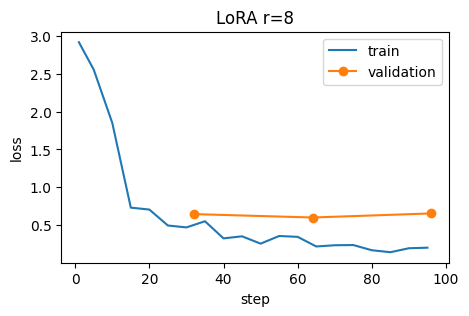

loss 2.915 -> 0.203
{'trainable': 6522880, 'minutes': 9.5, 'peak VRAM GB': 9.77}
[LoRA r=8] 33s {'EM': 74.0, 'F1': 80.1, 'abstain %': 74.0}


In [13]:
#@title Run A: LoRA r=8 — about 10 minutes (provided)

# Run A: LoRA r=8 on the Task 1 model
loaded = model.get_memory_footprint() / 2**30
lora_model = setup_lora(model, rank=8); trainable, total = count_params(lora_model)
print(f"trainable {trainable:,} / {total:,} = {100 * trainable / total:.2f}% | loaded weights {loaded:.2f} GB")
if not 6_000_000 < trainable < 7_000_000:
    raise ValueError(f"Expected about 6.5M trainable parameters, got {trainable:,}: check the rank and the target modules in setup_lora.")
torch.cuda.reset_peak_memory_stats(); trainer_a, minutes_a = train_once(lora_model, "lora"); plot_loss(trainer_a, "LoRA r=8")
lora_stats = {"trainable": trainable, "minutes": round(minutes_a, 1), "peak VRAM GB": round(torch.cuda.max_memory_allocated() / 2**30, 2)}; print(lora_stats)
results["LoRA r=8"], outputs["LoRA r=8"] = evaluate(lora_model, "LoRA r=8")
del trainer_a, lora_model, model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

trainable 6,522,880 / 657,527,936 = 0.99% (4-bit weights are packed) | loaded weights 1.47 GB


Epoch,Training Loss,Validation Loss
1,0.516151,0.707536
2,0.330384,0.621889
3,0.187692,0.683518


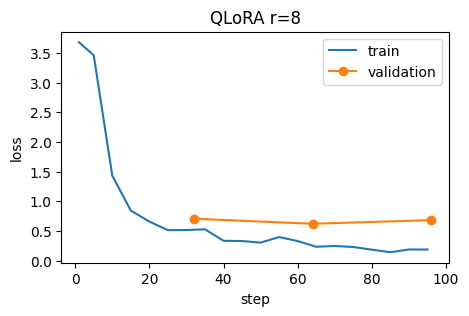

loss 3.682 -> 0.188
{'trainable': 6522880, 'minutes': 13.0, 'peak VRAM GB': 9.0}
[QLoRA r=8] 27s {'EM': 66.0, 'F1': 73.8, 'abstain %': 74.0}


In [14]:
#@title Run B: QLoRA r=8 — about 12 minutes (provided)

# Run B: QLoRA r=8, the same adapter on a 4-bit base
qlora_model = setup_qlora(MODEL_ID, rank=8); q_trainable, q_total = count_params(qlora_model)
print(f"trainable {q_trainable:,} / {q_total:,} = {100 * q_trainable / q_total:.2f}% (4-bit weights are packed) | loaded weights {qlora_model.get_memory_footprint() / 2**30:.2f} GB")
if q_trainable != trainable:
    raise ValueError("QLoRA must train the same adapter parameters as LoRA: setup_qlora should attach setup_lora with the same rank.")
torch.cuda.reset_peak_memory_stats(); trainer_b, minutes_b = train_once(qlora_model, "qlora"); plot_loss(trainer_b, "QLoRA r=8")
qlora_stats = {"trainable": q_trainable, "minutes": round(minutes_b, 1), "peak VRAM GB": round(torch.cuda.max_memory_allocated() / 2**30, 2)}; print(qlora_stats)
results["QLoRA r=8"], outputs["QLoRA r=8"] = evaluate(qlora_model, "QLoRA r=8")
del trainer_b, qlora_model; gc.collect(); torch.cuda.empty_cache()

In [15]:
#@title Results and full SQuAD examples (provided; CPU only)

# provided - run as is: the four tables for question 2.5
for name, stats in (("LoRA r=8", lora_stats), ("QLoRA r=8", qlora_stats)): results[name].update(stats)
print("1. Overall results (EM / F1 on the 50 answerable rows, abstain % on the 50 no-answer rows)"); display(pd.DataFrame(results).T)
print("2. Answerable examples (the gold column shows the first annotator answer only)"); display(side_by_side(outputs, ["Base", "LoRA r=8", "QLoRA r=8"], "answerable", n=10))
print("3. No-answer examples"); display(side_by_side(outputs, ["Base", "LoRA r=8", "QLoRA r=8"], "no answer", n=6))
refused = [i for i, r in enumerate(EVAL) if r["kind"] == "answerable" and outputs["LoRA r=8"][i]["abstain"] and not outputs["Base"][i]["abstain"]]
print(f"4. New refusals: {len(refused)} answerable questions the base model answered and LoRA refused (the base answer here is not necessarily correct)")
display(pd.DataFrame([{"question": EVAL[i]["question"][:70], "gold": EVAL[i]["answers"][0], "Base": outputs["Base"][i]["answer"][:50], "LoRA r=8": outputs["LoRA r=8"][i]["answer"][:50]} for i in refused]))

# provided: CPU only; inspect the predictions already generated in Task 2
def show_squad_evidence(i):
    row = EVAL[i]
    record = {"row_id": f"EVAL[{i}]", "kind": row["kind"], "question": row["question"],
              "context": row["context"], "accepted_answers": row["answers"]}
    record["systems"] = {
        name: {"raw": outputs[name][i]["raw"], "scored_answer": outputs[name][i]["answer"],
               "EM": em(outputs[name][i]["answer"], row["answers"]),
               "F1": f1(outputs[name][i]["answer"], row["answers"]),
               "abstain": bool(outputs[name][i]["abstain"])}
        for name in ("Base", "LoRA r=8", "QLoRA r=8")}
    print(json.dumps(record, ensure_ascii=False, indent=2))

def squad_task_correct(i, name):
    rec = outputs[name][i]
    if EVAL[i]["kind"] == "no answer":
        return bool(rec["abstain"])
    return em(rec["answer"], EVAL[i]["answers"]) == 100

evidence_squad_gains = [i for i in range(len(EVAL))
                       if squad_task_correct(i, "LoRA r=8") and not squad_task_correct(i, "Base")]
evidence_squad_losses = [i for i in range(len(EVAL))
                        if squad_task_correct(i, "Base") and not squad_task_correct(i, "LoRA r=8")]
print("LoRA improves: count =", len(evidence_squad_gains), "| EVAL ids =", evidence_squad_gains)
print("LoRA regresses: count =", len(evidence_squad_losses), "| EVAL ids =", evidence_squad_losses)
print("Selection rule: answerable -> EM; no answer -> abstain flag. These have different denominators.")
# Choose the rows you will discuss: put one or more EVAL ids from the lists above into SQUAD_EVIDENCE_IDS.
SQUAD_EVIDENCE_IDS = [50,5]
if not SQUAD_EVIDENCE_IDS:
    print("SQUAD_EVIDENCE_IDS is empty: add the ids you want to inspect and re-run this cell.")
for evidence_id in SQUAD_EVIDENCE_IDS:
    show_squad_evidence(evidence_id)

1. Overall results (EM / F1 on the 50 answerable rows, abstain % on the 50 no-answer rows)


,EM,F1,abstain %,trainable,minutes,peak VRAM GB
Base,64.0,79.4,24.0,NaN,NaN,NaN
LoRA r=8,74.0,80.1,74.0,6522880.0,9.5,9.77
QLoRA r=8,66.0,73.8,74.0,6522880.0,13.0,9.00


2. Answerable examples (the gold column shows the first annotator answer only)


,question,gold,Base,LoRA r=8,QLoRA r=8
0,What does a high tide risk near lands?,tear huge areas of land into the sea.,huge areas of land into the sea.,huge areas of land,serious risk
1,What caused the spread of the Jacksonville fir...,Spanish moss,Kitchen fire,kitchen fire,kitchen fire
2,What contributed to the severity of the plague?,"war, famine, and weather","war, famine, and weather","war, famine, and weather","war, famine, and weather"
3,What are the top 4-5% graduating students hono...,summa cum laude,Cum laude,summa cum laude,summa cum laude
4,When did Zhu publish 'Jade Mirror of the Four ...,1303,1303,1303,1303
5,Construction involves the translation of what?,designs into reality,designs into reality.,designs,designs
6,Why would a person chose civil disobedience ag...,"judged ""wrong"" by an individual conscience",to render certain laws ineffective,to render certain laws ineffective,to render certain laws ineffective
7,What has the United Nations designed ISIL?,a terrorist organisation,designated a terrorist organisation.,terrorist organisation,terrorist organisation
8,What percentage of leukocytes do neutrophils r...,50% to 60%,50% to 60%,50% to 60%,50% to 60%
9,What is the name of the university's core curr...,the Common Core,Common Core,Common Core,Common Core


3. No-answer examples


,question,gold,Base,LoRA r=8,QLoRA r=8
0,What is a transformation of two problems into ...,NOT IN CONTEXT,Cook reductions,NOT IN CONTEXT,NOT IN CONTEXT
1,Who is known for inventing the first elementar...,NOT IN CONTEXT,Robert A. Millikan,Robert A. Millikan,Robert A. Millikan
2,"How many joined the ""network""?",NOT IN CONTEXT,Several universities,several,several
3,How did Fielding H. Garrison believe land was ...,NOT IN CONTEXT,Based on his observation of fossil animal shel...,NOT IN CONTEXT,erosion
4,When did BSkyB upgrade the Sky+ Box?,NOT IN CONTEXT,1 July 2007,1 July 2007,1 July 2007
5,Who argued for including the graph in the fina...,NOT IN CONTEXT,The Bush administration,NOT IN CONTEXT,NOT IN CONTEXT


4. New refusals: 3 answerable questions the base model answered and LoRA refused (the base answer here is not necessarily correct)


,question,gold,Base,LoRA r=8
0,"Other than the Ijssel, where does the water fr...",Nederrijn,IJsselmeer,NOT IN CONTEXT
1,Who decides the fate of protesters most of the...,the state,The state,NOT IN CONTEXT
2,What is an example of a measurement within a c...,computation time,relaxing the requirements on computation time,NOT IN CONTEXT


LoRA improves: count = 32 | EVAL ids = [3, 7, 10, 23, 29, 43, 47, 50, 53, 55, 58, 60, 61, 64, 66, 67, 69, 70, 72, 74, 79, 80, 83, 84, 88, 89, 91, 92, 94, 95, 96, 99]
LoRA regresses: count = 2 | EVAL ids = [5, 37]
Selection rule: answerable -> EM; no answer -> abstain flag. These have different denominators.
{
  "row_id": "EVAL[50]",
  "kind": "no answer",
  "question": "What is a transformation of two problems into on three problems?",
  "context": "Many complexity classes are defined using the concept of a reduction. A reduction is a transformation of one problem into another problem. It captures the informal notion of a problem being at least as difficult as another problem. For instance, if a problem X can be solved using an algorithm for Y, X is no more difficult than Y, and we say that X reduces to Y. There are many different types of reductions, based on the method of reduction, such as Cook reductions, Karp reductions and Levin reductions, and the bound on the complexity of redu

### **2.5 Discussion (14 pts)**

**A. What changed through training? (8 pts)**

Start with the numbers: from Base to LoRA, how much did EM, F1 and abstain % change, and on which denominators? Then use
the viewer to find two questions, one that got better after fine-tuning and one that got worse. Give their ids and say
what "better" means for each (EM against all gold answers for an answerable question, refusing for a no-answer question).

Next, a question to think through, not to run: if the prompt positions in `labels` held the prompt's own token ids
instead of `-100`, what extra would enter the loss, and would training still be about the answer only?

Finally, from the two questions you picked, what did fine-tuning change: the content of the answer, its form, or the
tendency to refuse? Also name one thing these two examples are not enough to prove.

**Your answer A:**

From Base to LoRA, EM went from 64.0 to 74.0 (+10 points) and F1 from 79.4 to 80.1 (+0.7). Both are computed only on the 50 answerable rows, so EM went from about 32 to 37 exact answers. Abstain % went from 24.0 to 74.0 (+50 points), but this is computed only on the 50 no-answer rows: the model correctly refused on 37 of them instead of 12. Overall, the viewer reports 32 improved rows and 2 regressed rows (ids 5 and 37).

Better: id 50 (no-answer). The question was "What is a transformation of two problems into on three problems?", and the only gold answer is NOT IN CONTEXT. Base replied "Cook reductions", a confident answer taken from a related passage. LoRA replied "NOT IN CONTEXT". For a no-answer question, "better" means refusing, so this is an improvement. It's the same question that no prompt could make the model refuse in Task 1.

Worse: id 5 (answerable). The question was "Construction involves the translation of what?", and all three accepted gold answers are "designs into reality". Base replied "designs into reality.", which matches the gold once punctuation is removed (EM = 100). LoRA replied only "designs", which matches none of the gold answers (EM = 0). For an answerable question, "better" means EM against all gold answers, so this got worse.

If the prompt positions in labels held the prompt's own token ids instead of −100, the loss would also include predicting the chat template, my instruction, the whole passage and the question. The prompt is hundreds of tokens and the answer only a few, so most of the loss would come from reproducing the passage text, and the answer signal would be diluted. Training would no longer be about the answer only; it would partly become ordinary language modeling on Wikipedia text.

From these two examples, fine-tuning mainly changed the form and the tendency to refuse, not the content. In id 50, the model learned to refuse instead of grabbing a related term. In id 5, it learned to give very short spans, which here cut the answer too short. This also fits the numbers: EM rose 10 points but F1 barely moved, so answers got shorter and more exact rather than more knowledgeable. These two examples are not enough to prove that the refusals reflect real understanding of when the answer is missing. The results table shows LoRA also refused on 3 answerable questions that Base had answered, so part of the higher abstain % may be a general tendency to refuse more, which two examples can't separate from genuine detection.
















**B. Does 4-bit mean 75% less of everything? (6 pts)**

Compare the three numbers printed by the two runs: the loaded model size, the peak training memory and the minutes. Then
explain which part of the model the quantization applies to and whether the other training costs shrink with it.
Support your explanation with one concrete fact you can see in the code or the outputs, and say what this comparison
cannot tell you.

**Your answer B:**

The loaded model size went from 1.86 GB for LoRA to 1.47 GB for QLoRA, only about 21% smaller. Peak training memory was 9.65 GB for LoRA in my first run (results table) and 8.94 GB for QLoRA, about 7% less. Training time went up from 9.8 to 11.7 minutes, about 19% slower. After a disconnect I had to retrain LoRA once more. It gave the same scores (EM 74.0, F1 80.1, abstain 74.0) but took 9.5 minutes and peaked at 11.51 GB, which shows that the peak number also depends on what else is in GPU memory at the time. Either way, 4-bit does not mean 75% less of everything.

Quantization applies only to the frozen base model weights. Quantization reduces storage for the quantized base weights. Adapter parameters, gradients, optimizer states, and activations are not automatically reduced to 4-bit and can use different precisions. With sequences up to 512 tokens, these make up most of the peak memory, so compressing the weights saves relatively little. Training even gets slower, because the code sets bnb_4bit_compute_dtype=torch.float16: the 4-bit weights are stored compactly but must be unpacked to 16-bit for every calculation. The output shows the packing directly. LoRA reports 1,006,408,832 total parameters, while QLoRA reports 657,527,936 with the note "(4-bit weights are packed)", even though it is the same model. The loaded size also shrank by only about 21% rather than 75%, probably because some parts of the model are not quantized, but these outputs can't confirm which ones.

This comparison cannot tell us how the results scale. It is one run of a small 1B model on one GPU type (a T4), and my two LoRA runs already gave different peak memory. For a much larger model, the weights would be a bigger share of memory, so QLoRA's savings could be much larger. The accuracy gap (EM 74.0 for LoRA vs 66.0 for QLoRA) also comes from single runs, so we can't tell how much of it is caused by 4-bit compression and how much is random variation between runs.

In [ ]:
#@title Optional backup: download the LoRA adapter for Task 4 (not submitted)

shutil.make_archive("/content/adapter_lora", "zip", "/content/adapter_lora")
try:
    from google.colab import files; files.download("/content/adapter_lora.zip")
except Exception as e: print("download it from the Files pane:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Task 3: Retrieve with BM25 (25 pts)**

In this task, you will switch to a different dataset. Upload the provided `rag_hard_set_sciq.json`: 12,241 science
paragraphs and 150 questions. The questions were selected because they are hard to answer without the passage, so they
do not represent SciQ as a whole.

You will compare five settings with the same prompt: no passage at all (closed-book), the top 1 / 3 / 5 paragraphs
retrieved by BM25, and the gold paragraph itself (oracle).

Recall@k is the retriever's own metric: the share of questions whose gold paragraph is among the first k retrieved ids.
No model is involved. EM, F1 and abstain % are computed on all 150 questions in this task, and abstain % here only
describes behaviour; it is not good or bad by itself. One more thing to keep in mind: "the gold paragraph was not
retrieved" does not mean "the answer is not in the retrieved text", because the library contains paragraphs with
overlapping content.

Helpers: use `format_qa` for prompts with passages and `format_closed` for the no-passage prompt.
`score(model, prompts, k)` generates with `chat` and returns a summary and the per-question records. Evaluating all
five settings takes about five minutes.

###**Grading Breakdown:**
1. BM25 index and `retrieve` (7 pts)
2. `recall_at_k` (4 pts)
3. `build_rag_prompt` and `make_input` (4 pts)
4. Discussion (10 pts)

Refer to the following guide:
1. [rank_bm25](https://github.com/dorianbrown/rank_bm25#usage)

<details><summary>Only after a disconnect: restore the adapter</summary>

Redo the setup, run Task 1 again up to the cell that defines `train_once`, and skip the two training runs and the
Task 2 results and backup cells. Set `RECOVER_FROM_ZIP=True` in the cell below, upload your saved `adapter_lora.zip`,
and continue from there.

</details>

In [16]:
#@title Optional recovery after a disconnect (provided; otherwise leave False)

RECOVER_FROM_ZIP = False      # True only after a disconnect, to restore adapter_lora.zip
if RECOVER_FROM_ZIP:
    from google.colab import files
    up = files.upload(); shutil.unpack_archive("/content/" + next(n for n in up if n.endswith(".zip")), "/content/adapter_lora")
    print("restored:", sorted(os.listdir("/content/adapter_lora")))
    if "model" in globals(): del model; gc.collect(); torch.cuda.empty_cache()

Saving adapter_lora.zip to adapter_lora.zip
restored: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']


In [17]:
#@title Upload the SciQ file and load a fresh Base model (provided)

# upload rag_hard_set_sciq.json (provided with the assignment) when the dialog opens; re-run after any runtime reset
from rank_bm25 import BM25Okapi
HARD_SET_PATH = "/content/rag_hard_set_sciq.json"
if not os.path.exists(HARD_SET_PATH):
    from google.colab import files
    for name in files.upload():
        if name.endswith(".json"): shutil.move("/content/" + name, HARD_SET_PATH)
data = json.load(open(HARD_SET_PATH))
library, hard = data["corpus"], data["questions"]       # paragraphs (id = index) | question, answers, gold_doc
def format_closed(question):
    """Provided: no-retrieval prompt; keep the same QA instruction, with an empty-context placeholder."""
    return format_qa("[No retrieved context]", question)

model = load_model(MODEL_ID)[1]                           # a fresh base model; the Task 1 tokenizer is kept
print(f"library: {len(library)} paragraphs | questions: {len(hard)}")
q = hard[0]; print(f"\nQ: {q['question']}\n  gold: {q['answers'][0]}\n  gold paragraph: {library[q['gold_doc']][:140]}...")

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

library: 12241 paragraphs | questions: 150

Q: During what process is light from the star focused and the star appears to brighten in a characteristic manner?
  gold: microlensing
  gold paragraph: In a process called microlensing, light from the star is focused and the star appears to brighten in a characteristic manner. Searches for d...


In [18]:
# 3.1 Build BM25 and retrieve document IDs (7 pts)

import re
import numpy as np
from rank_bm25 import BM25Okapi

def bm25_tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())


# Build the BM25 index
tokenized_library = [bm25_tokenize(p) for p in library]
bm25 = BM25Okapi(tokenized_library)


def retrieve(question, k=5):
    # Calculate BM25 relevance scores
    scores = bm25.get_scores(bm25_tokenize(question))

    # Sort documents from highest to lowest score
    top = np.argsort(scores)[::-1][:k]

    # Return document IDs
    return [int(i) for i in top]


# Retrieve and cache the top 5 documents for every hard question
for q in hard:
    q["retrieved"] = retrieve(q["question"], k=5)


# Display results for the first question
q = hard[0]

print("Question:", q["question"])
print("Gold document:", q["gold_doc"])

for rank, i in enumerate(q["retrieved"][:3], 1):
    marker = " <== GOLD" if i == q["gold_doc"] else ""
    print(f"{rank}. [{i}]{marker} {library[i][:100]}...")


def recall_at_k(hard, k):
    hits = 0

    for q in hard:
        if q["gold_doc"] in q["retrieved"][:k]:
            hits += 1

    return hits / len(hard)


print("\n--- BM25 Retrieval Performance ---")

for k in [1, 3, 5]:
    score = recall_at_k(hard, k)
    print(f"Recall@{k}: {score:.2%}")

Question: During what process is light from the star focused and the star appears to brighten in a characteristic manner?
Gold document: 11020
1. [11020] <== GOLD In a process called microlensing, light from the star is focused and the star appears to brighten in...
2. [2805] Within a nebula, there are varying regions where gravity has caused the gas and dust to clump togeth...
3. [7002] After a star becomes a red giant, it will take one of several different paths to end its life. Which...

--- BM25 Retrieval Performance ---
Recall@1: 77.33%
Recall@3: 91.33%
Recall@5: 93.33%


In [22]:
# 3.2 Measure Recall@k (4 pts)

def recall_at_k(k):
    """
    Args:
        k: number of retrieved paragraphs to look at
    Returns:
        recall: percentage of questions in `hard` whose gold paragraph
                is among the first k retrieved ids
    """
    hits = 0

    for q in hard:
        if q["gold_doc"] in q["retrieved"][:k]:
            hits += 1

    recall = 100 * hits / len(hard)

    return recall


recalls = [recall_at_k(k) for k in (1, 3, 5)]

for k, r in zip((1, 3, 5), recalls):
    print(f"Recall@{k} = {r:5.1f}%")

if not 60 <= recalls[0] <= recalls[1] <= recalls[2] <= 100:
    raise ValueError(
        "Retriever check failed: check the BM25 tokenization "
        "(a list of token lists, not strings) and that the "
        "scores are sorted from high to low."
    )

Recall@1 =  77.3%
Recall@3 =  91.3%
Recall@5 =  93.3%


In [23]:
# 3.3 Build RAG inputs (4 pts)

def build_rag_prompt(passages, question):
    """
    Args:
        passages: list of paragraph texts
        question: the question text
    Returns:
        prompt: the format_qa prompt whose context is the numbered passages
    """
    parts = []

    for i, passage in enumerate(passages, 1):
        parts.append(f"[{i}] {passage}")

    context = "\n\n".join(parts)

    prompt = format_qa(context, question)

    return prompt


def make_input(row, k):
    """
    Args:
        row: one question of `hard`
        k: number of retrieved paragraphs to put in the prompt
        0 means no retrieval
    Returns:
        prompt: the prompt for this question
    """
    if k == 0:
        prompt = format_closed(row["question"])
    else:
        retrieved_ids = row["retrieved"][:k]
        passages = [library[i] for i in retrieved_ids]

        prompt = build_rag_prompt(passages, row["question"])

    return prompt


# Provided check
_q = hard[0]

if (make_input(_q, 0) != format_closed(_q["question"])
        or library[_q["retrieved"][0]] not in make_input(_q, 1)):
    raise ValueError(
        "make_input check failed: k = 0 must give format_closed(question); "
        "k = 1 must contain the text of the top-1 paragraph."
    )


# Oracle check: use the gold passage directly
check_rows = hard[:10]

check_prompts = [
    build_rag_prompt(
        [library[q["gold_doc"]]],
        q["question"]
    )
    for q in check_rows
]

check_replies = chat(
    model,
    check_prompts,
    max_new_tokens=24
)

_ok = sum(
    em(first_line(reply), q["answers"]) == 100.0
    for reply, q in zip(check_replies, check_rows)
)

print(
    f"sanity check: {_ok}/10 gold-passage questions "
    f"answered exactly right (about 9 expected)"
)

sanity check: 9/10 gold-passage questions answered exactly right (about 9 expected)


In [24]:
#@title Evaluate five retrieval settings — about five minutes (provided)

# provided - run as is: score a list of prompts (one per question of `hard`), then the five settings of Task 3
def score(model, prompts, k):
    """Provided: prompt list -> (summary, records). k=0: no retrieval; None: oracle."""
    outs = chat(model, prompts, max_new_tokens=32)  # generation receives prompts, not gold answers
    recs = []
    for q, raw in zip(hard, outs):
        answer = first_line(raw)
        golds = q["answers"]  # read only AFTER generation, for scoring
        hit = True if k is None else q["gold_doc"] in q["retrieved"][:k]
        recs.append({"question": q["question"], "gold": golds, "raw": raw, "answer": answer,
                     "em": em(answer, golds), "f1": f1(answer, golds),
                     "abstain": is_abstain(raw), "hit": hit})
    s = {"Recall@k": round(100 * st.mean(r["hit"] for r in recs), 1), "EM": round(st.mean(r["em"] for r in recs), 1),
         "F1": round(st.mean(r["f1"] for r in recs), 1), "abstain %": round(100 * st.mean(r["abstain"] for r in recs), 1)}
    print("  ", s)
    return s, recs

rag_results, rag_outputs = {}, {}
prompts = [make_input(q, 0) for q in hard]
rag_results["closed-book"], rag_outputs["closed-book"] = score(model, prompts, 0)
for k in (1, 3, 5):
    prompts = [make_input(q, k) for q in hard]
    rag_results[f"BM25 top-{k}"], rag_outputs[f"BM25 top-{k}"] = score(model, prompts, k)
prompts = [build_rag_prompt([library[q["gold_doc"]]], q["question"]) for q in hard]
rag_results["oracle"], rag_outputs["oracle"] = score(model, prompts, None)
rag_table = pd.DataFrame(rag_results).T
display(rag_table)


   {'Recall@k': 0, 'EM': 0.7, 'F1': 3.2, 'abstain %': 28.7}
   {'Recall@k': 77.3, 'EM': 80.7, 'F1': 82.7, 'abstain %': 2.7}
   {'Recall@k': 91.3, 'EM': 69.3, 'F1': 75.8, 'abstain %': 0.7}
   {'Recall@k': 93.3, 'EM': 58.7, 'F1': 69.9, 'abstain %': 2.0}
   {'Recall@k': 100, 'EM': 93.3, 'F1': 94.6, 'abstain %': 0}


,Recall@k,EM,F1,abstain %
closed-book,0.0,0.7,3.2,28.7
BM25 top-1,77.3,80.7,82.7,2.7
BM25 top-3,91.3,69.3,75.8,0.7
BM25 top-5,93.3,58.7,69.9,2.0
oracle,100.0,93.3,94.6,0.0


In [25]:
#@title Paired hit@1 results and full RAG example (provided; CPU only)



# provided: CPU only; compare the SAME hit@1 questions using cached Task 3 predictions
evidence_hit1 = [i for i, rec in enumerate(rag_outputs["BM25 top-1"]) if rec["hit"]]
evidence_rag_summary = []
for evidence_k in (1, 3, 5):
    evidence_rs = [rag_outputs[f"BM25 top-{evidence_k}"][i] for i in evidence_hit1]
    evidence_rag_summary.append({
        "k": evidence_k, "same hit@1 questions": len(evidence_rs),
        "EM correct count": sum(r["em"] == 100 for r in evidence_rs),
        "EM": st.mean(r["em"] for r in evidence_rs) if evidence_rs else None,
        "F1": st.mean(r["f1"] for r in evidence_rs) if evidence_rs else None,
        "abstain count": sum(bool(r["abstain"]) for r in evidence_rs)})
display(pd.DataFrame(evidence_rag_summary))
evidence_rag_pairs = Counter(
    (rag_outputs["BM25 top-1"][i]["em"] == 100, rag_outputs["BM25 top-5"][i]["em"] == 100)
    for i in evidence_hit1)
display(pd.DataFrame([
    {"top-1 EM correct": a, "top-5 EM correct": b, "count": evidence_rag_pairs[a, b]}
    for a in (True, False) for b in (True, False)]))
evidence_rag_losses = [i for i in evidence_hit1
                      if rag_outputs["BM25 top-1"][i]["em"] == 100
                      and rag_outputs["BM25 top-5"][i]["em"] != 100]
print("hit@1 correct -> incorrect ids:", evidence_rag_losses, "| count:", len(evidence_rag_losses))

def show_rag_evidence(i):
    q = hard[i]
    record = {"row_id": f"hard[{i}]", "question": q["question"], "accepted_answers": q["answers"],
              "gold_doc": q["gold_doc"], "retrieved_doc_ids": q["retrieved"],
              "gold_paragraph": library[q["gold_doc"]],
              "prompt_top1": make_input(q, 1), "prompt_top5": make_input(q, 5),
              "outputs": {f"top-{k}": rag_outputs[f"BM25 top-{k}"][i] for k in (1, 3, 5)}}
    print(json.dumps(record, ensure_ascii=False, indent=2))

# Choose the row you will discuss: put one or more ids from the lists above into RAG_EVIDENCE_IDS.
RAG_EVIDENCE_IDS = [1]
if not RAG_EVIDENCE_IDS:
    print("RAG_EVIDENCE_IDS is empty: add the ids you want to inspect and re-run this cell.")
for evidence_id in RAG_EVIDENCE_IDS:
    show_rag_evidence(evidence_id)

,k,same hit@1 questions,EM correct count,EM,F1,abstain count
0,1,116,110,94.827586,96.227336,0
1,3,116,86,74.137931,81.412309,0
2,5,116,75,64.655172,75.123290,1


,top-1 EM correct,top-5 EM correct,count
0,True,True,72
1,True,False,38
2,False,True,3
3,False,False,3


hit@1 correct -> incorrect ids: [1, 9, 11, 17, 18, 20, 21, 35, 36, 38, 40, 42, 49, 51, 53, 60, 62, 64, 65, 66, 69, 71, 88, 92, 99, 112, 117, 120, 121, 126, 130, 131, 134, 137, 139, 141, 144, 147] | count: 38
{
  "row_id": "hard[1]",
  "question": "Formic acid is found in the secretions of?",
  "accepted_answers": [
    "stinging ants"
  ],
  "gold_doc": 330,
  "retrieved_doc_ids": [
    330,
    8917,
    3874,
    1630,
    5335
  ],
  "gold_paragraph": "where R can be an alkyl group, an aryl group, or a hydrogen atom. The simplest example, HCO2H, is formic acid, so called because it is found in the secretions of stinging ants (from the Latin formica, meaning “ant”). Another example is acetic acid(CH3CO2H), which is found in vinegar. Like many acids, carboxylic acids tend to have sharp odors. For example, butyric acid (CH3CH2CH2CO2H), is responsible for the smell of rancid butter, and the characteristic odor of sour milk and vomit is due to lactic acid [CH3CH(OH)CO2H]. Some common car

In [ ]:
print("EVAL[5] all gold answers:", EVAL[5]["answers"])
q = hard[3]
print("\nhard[3] top-1 retrieved paragraph (id", q["retrieved"][0], "):\n", library[q["retrieved"][0]])

EVAL[5] all gold answers: ['designs into reality', 'designs into reality', 'designs into reality']

hard[3] top-1 retrieved paragraph (id 7179 ):
 Types of Root Systems Root systems are mainly of two types (Figure 30.15). Dicots have a tap root system, while monocots have a fibrous root system. A tap root system has a main root that grows down vertically, and from which many smaller lateral roots arise. Dandelions are a good example; their tap roots usually break off when trying to pull these weeds, and they can regrow another shoot from the remaining root). A tap root system penetrates deep into the soil. In contrast, a fibrous root system is located closer to the soil surface, and forms a dense network of roots that also helps prevent soil erosion (lawn grasses are a good example, as are wheat, rice, and corn). Some plants have a combination of tap roots and fibrous roots. Plants that grow in dry areas often have deep root systems, whereas plants growing in areas with abundant water 

### **3.4 Discussion (10 pts)**

First compare the five settings: as k grows, which way do Recall, EM, F1 and abstain % move? Based on that, say which
`K` you will use in Task 4 and why.

Then look at the set of questions the viewer reports as *gold paragraph at rank 1*: how many are there? On these
questions, when you go from top-1 to top-5, how many change from correct to incorrect and how many from incorrect to
correct? Report both directions.

Pick one question that went from correct to incorrect (if there is none, use the fallback described at the top). Read
both of its prompts and both replies and explain why the answer changed; if you cannot tell, say what you cannot tell.
Finally, use this question to test one other explanation you find plausible, and name one thing that remains
undetermined.

**Your answer (include the row id):**

As k grows from 1 to 3 to 5, Recall goes up (77.3 → 91.3 → 93.3%), but EM goes down (80.7 → 69.3 → 58.7) and F1 goes down too (82.7 → 75.8 → 69.9). Abstain % stays low with no clear trend (2.7 → 0.7 → 2.0). For comparison, closed-book EM is only 0.7 and the oracle reaches 93.3, so the passage is essential and the model reads a correct passage well. More paragraphs make it more likely that the gold paragraph is in the prompt, but the extra paragraphs seem to distract this small model. I will use K = 1 in Task 4, because it has the highest EM and F1. Going from top-3 to top-5 adds only 2 points of recall, while EM keeps falling.

The viewer reports 116 questions whose gold paragraph is at rank 1. On these same 116 questions, the model was correct on 110 at top-1, 86 at top-3 and 75 at top-5. From top-1 to top-5, 38 questions changed from correct to incorrect, and only 3 changed from incorrect to correct (72 stayed correct and 3 stayed incorrect). Because the gold paragraph is first in both prompts, these losses cannot come from retrieval failing. They come from adding the four extra paragraphs.

Row hard[1]: "Formic acid is found in the secretions of?", with the accepted answer "stinging ants". In both prompts, paragraph [1] is the gold paragraph, which says formic acid "is found in the secretions of stinging ants". With top-1 the model replied "Stinging ants" (EM = 100). With top-5 it replied only "where" (EM = 0), and the top-3 reply was also "where". The top-5 prompt adds [2], which says formic acid "makes certain ant bites sting", [3], which says it is "found in the stingers of ants", and two unrelated paragraphs, [4] on amino acids and [5] on sulfuric acid. The reply "where" is not taken from any of the added paragraphs: it is the very first word of paragraph [1] ("where R can be an alkyl group…"). So with the longer context, the model stopped locating the answer and simply copied the beginning of the context. One other plausible explanation is that the model picked up a reworded version of the answer from [2] or [3], such as "ant bites" or "stingers of ants". This question does not support that, because the reply contains none of their wording. It also shows that the unrelated paragraphs [4] and [5] are not needed for the failure, because the top-3 prompt, which only adds [2] and [3], already gives "where". What remains undetermined is whether the problem is caused by the content of the added paragraphs (two more passages about formic acid and ants) or simply by the longer prompt. Testing that would need, for example, the same question with two unrelated paragraphs of similar length added instead.

## **Task 4: Combine Fine-Tuning and Retrieval (20 pts)**

In this task, the two lines come together. Load the LoRA adapter you saved in Task 2, use the `K` you chose in Task 3,
and run a 2 × 2 comparison on the same 150 questions:

| | No RAG | BM25 top-K |
|---|---|---|
| Base | Base | Base + RAG |
| Fine-tuned | LoRA | LoRA + RAG |

The scoring is the same as in Task 3 and takes about three minutes. The provided tables also line up the two models on
the same questions whose gold paragraph was not retrieved, so you can see what each did with the same input.

###**Grading Breakdown:**
1. `load_finetuned` (3 pts)
2. Completing the 2 × 2 (4 pts)
3. Discussion A (6 pts) and Discussion B (7 pts)

Refer to the following guide:
1. [Loading a PEFT adapter](https://huggingface.co/docs/peft/quicktour#inference)

In [26]:
# 4.1  Load the saved LoRA adapter (3 pts)

from peft import PeftModel

def load_finetuned(adapter_dir):
    # load a fresh original Gemma (we already have a tokenizer, so ignore the returned one)
    _, base = load_model(MODEL_ID)
    # attach the saved LoRA adapter from Task 2
    ft = PeftModel.from_pretrained(base, adapter_dir)
    return ft

ft = load_finetuned("/content/adapter_lora")
print("LoRA parameters attached:", sum(p.numel() for n, p in ft.named_parameters() if "lora" in n))

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

LoRA parameters attached: 6522880


In [27]:
# 4.2  Choose K and evaluate the 2 × 2 (4 pts)

import pandas as pd

K = 1      # ← CHANGE to the K you chose in your Task 3 discussion (1, 3 or 5)

grid_results, grid_outputs = {}, {}
for name, m in (("Base", model), ("Fine-tuned", ft)):
    for setting, k in (("no RAG", 0), ("RAG", K)):
        prompts = [make_input(row, k) for row in hard]
        summary, records = score(m, prompts, k)
        grid_results[f"{name} / {setting}"] = summary
        grid_outputs[f"{name} / {setting}"] = records

grid_table = pd.DataFrame(grid_results).T
print(f"Exact Match on the {len(hard)} SciQ questions")
display(pd.DataFrame({"no RAG": [grid_results["Base / no RAG"]["EM"], grid_results["Fine-tuned / no RAG"]["EM"]],
                      f"RAG (BM25 top-{K})": [grid_results["Base / RAG"]["EM"], grid_results["Fine-tuned / RAG"]["EM"]]}, index=["Base", "Fine-tuned"]))
display(grid_table)

   {'Recall@k': 0, 'EM': 0.7, 'F1': 3.2, 'abstain %': 28.7}
   {'Recall@k': 77.3, 'EM': 80.7, 'F1': 82.7, 'abstain %': 2.7}
   {'Recall@k': 0, 'EM': 3.3, 'F1': 4.2, 'abstain %': 62.7}
   {'Recall@k': 77.3, 'EM': 79.3, 'F1': 82.8, 'abstain %': 8.7}
Exact Match on the 150 SciQ questions


,no RAG,RAG (BM25 top-1)
Base,0.7,80.7
Fine-tuned,3.3,79.3


,Recall@k,EM,F1,abstain %
Base / no RAG,0.0,0.7,3.2,28.7
Base / RAG,77.3,80.7,82.7,2.7
Fine-tuned / no RAG,0.0,3.3,4.2,62.7
Fine-tuned / RAG,77.3,79.3,82.8,8.7


In [28]:
#@title Hit/miss results, paired transitions and full example (provided; CPU only)

# provided - run as is: the hit / miss split; empty groups show None/NA
B, F = grid_outputs["Base / RAG"], grid_outputs["Fine-tuned / RAG"]
rows = []
for name, rs in (("Base + RAG", B), ("Fine-tuned + RAG", F)):
    h, m = [r for r in rs if r["hit"]], [r for r in rs if not r["hit"]]
    rows.append({"system": name, "hits": len(h), "EM on hits": round(st.mean(r["em"] for r in h), 1) if h else None, "misses": len(m), "EM on misses": round(st.mean(r["em"] for r in m), 1) if m else None,
                 "abstain % on misses": round(100 * st.mean(r["abstain"] for r in m), 1) if m else None, "wrong guess % on misses": round(100 * st.mean((not r["abstain"]) and r["em"] == 0 for r in m), 1) if m else None})
display(pd.DataFrame(rows))
misses = [i for i, r in enumerate(F) if not r["hit"]][:8]
display(pd.DataFrame([{"question": F[i]["question"][:60], "gold": F[i]["gold"][0], "Base + RAG": B[i]["raw"][:60], "Fine-tuned + RAG": F[i]["raw"][:60]} for i in misses]))

# provided: CPU only; pair Base and Fine-tuned predictions on the SAME gold-doc misses
def evidence_rag_state(rec):
    if rec["em"] == 100 and rec["abstain"]:
        return "EM match + abstain (inspect)"
    if rec["em"] == 100:
        return "EM match"
    return "abstain" if rec["abstain"] else "wrong guess"

evidence_base = grid_outputs["Base / RAG"]
evidence_ft = grid_outputs["Fine-tuned / RAG"]
if len(evidence_base) != len(evidence_ft) or any(
    b["question"] != f["question"] or b["hit"] != f["hit"]
    for b, f in zip(evidence_base, evidence_ft)):
    raise ValueError("Paired evidence requires the same questions and retrieval settings.")
evidence_miss_ids = [i for i, rec in enumerate(evidence_base) if not rec["hit"]]
evidence_grid_margins = []
for evidence_name, evidence_records in (("Base", evidence_base), ("Fine-tuned", evidence_ft)):
    evidence_rs = [evidence_records[i] for i in evidence_miss_ids]
    evidence_grid_margins.append({
        "system": evidence_name, "misses": len(evidence_rs),
        "EM match count": sum(r["em"] == 100 for r in evidence_rs),
        "abstain count": sum(bool(r["abstain"]) for r in evidence_rs),
        "wrong guess count": sum(not r["abstain"] and r["em"] == 0 for r in evidence_rs)})
display(pd.DataFrame(evidence_grid_margins))
evidence_grid_pairs = Counter(
    (evidence_rag_state(evidence_base[i]), evidence_rag_state(evidence_ft[i]))
    for i in evidence_miss_ids)
evidence_states = ["EM match", "abstain", "wrong guess"]
if any("EM match + abstain (inspect)" in pair for pair in evidence_grid_pairs):
    evidence_states.append("EM match + abstain (inspect)")
display(pd.DataFrame([[evidence_grid_pairs[a, b] for b in evidence_states]
                      for a in evidence_states], index=evidence_states, columns=evidence_states)
        .rename_axis(index="Base", columns="Fine-tuned"))
print("Rows with both an EM match and an abstain flag are separated for inspection, if present.")
evidence_wrong_to_abstain = [i for i in evidence_miss_ids
    if evidence_rag_state(evidence_base[i]) == "wrong guess"
    and evidence_rag_state(evidence_ft[i]) == "abstain"]
print("wrong guess -> abstain ids:", evidence_wrong_to_abstain,
      "| count:", len(evidence_wrong_to_abstain))

def show_grid_evidence(i):
    q = hard[i]
    record = {"row_id": f"hard[{i}]", "question": q["question"], "accepted_answers": q["answers"],
              "gold_doc": q["gold_doc"], "retrieved_doc_ids": q["retrieved"][:K],
              "prompt_used_by_both": make_input(q, K),
              "Base": evidence_base[i], "Fine-tuned": evidence_ft[i]}
    print(json.dumps(record, ensure_ascii=False, indent=2))

# Choose the row you will discuss: put one or more ids from the lists above into GRID_EVIDENCE_IDS.
GRID_EVIDENCE_IDS = [3, 33]
if not GRID_EVIDENCE_IDS:
    print("GRID_EVIDENCE_IDS is empty: add the ids you want to inspect and re-run this cell.")
for evidence_id in GRID_EVIDENCE_IDS:
    show_grid_evidence(evidence_id)

,system,hits,EM on hits,misses,EM on misses,abstain % on misses,wrong guess % on misses
0,Base + RAG,116,94.8,34,32.4,11.8,55.9
1,Fine-tuned + RAG,116,93.1,34,32.4,38.2,29.4


,question,gold,Base + RAG,Fine-tuned + RAG
0,"Grasses such as wheat, rice, and corn are exam...",dicots,fibrous root systems are found in monocots.,NOT IN CONTEXT
1,What is the name of a joint in which one bone ...,pivot joint,elbow,elbow
2,Name the fibrous joint in which two parallel b...,syndesmosis,Suture,gomphesis
3,Amino acids are made by which kind of plastid?,leucoplasts,Not in context.,NOT IN CONTEXT
4,What device is used to study charge?,electroscope,19.5 Capacitors and Dielectrics,NOT IN CONTEXT
5,What monitors the level of carbon dioxide in t...,the brain stem,The brain stem,the brain stem
6,What goes through different larval stages?,crustaceans,NOT IN CONTEXT,NOT IN CONTEXT
7,How many main types of diabetes are there?,two,Two,two


,system,misses,EM match count,abstain count,wrong guess count
0,Base,34,11,4,19
1,Fine-tuned,34,11,13,10


Fine-tuned,EM match,abstain,wrong guess
Base,,,
EM match,10,0,1
abstain,0,4,0
wrong guess,1,9,9


Rows with both an EM match and an abstain flag are separated for inspection, if present.
wrong guess -> abstain ids: [3, 33, 74, 75, 91, 96, 100, 107, 111] | count: 9
{
  "row_id": "hard[3]",
  "question": "Grasses such as wheat, rice, and corn are examples of fibrous root systems. fibrous root systems are found in monocots; tap root systems are found in these?",
  "accepted_answers": [
    "dicots"
  ],
  "gold_doc": 1867,
  "retrieved_doc_ids": [
    7179
  ],
  "prompt_used_by_both": "Answer the question using ONLY the context below.\nReply with the shortest exact span copied from the context. If the context does not answer the question, reply NOT IN CONTEXT. Do not explain.\n\nContext:\n[1] Types of Root Systems Root systems are mainly of two types (Figure 30.15). Dicots have a tap root system, while monocots have a fibrous root system. A tap root system has a main root that grows down vertically, and from which many smaller lateral roots arise. Dandelions are a good example; their

### **4.3 Discussion (13 pts)**

**A. What does the 2 × 2 show? (6 pts)**

Using your four numbers: how much does adding retrieval change, how much does switching to the fine-tuned model change,
and which of the two changes **x** and which changes **θ**?

Then assess this claim: "The low EM without retrieval shows that fine-tuning taught the model no new facts." Look at the
prompt that the no-RAG cell actually uses and think about what it measures; then state a more careful conclusion that
your data does support. Finally, design a small experiment that would test the claim: keep everything else fixed, change
one thing, and say what the different outcomes would mean. Describe it; do not run it.

**Your answer A:**

Adding retrieval (BM25 top-1) is by far the larger change. EM rose from 0.7 to 80.7 for Base (+80.0) and from 3.3 to 79.3 for the fine-tuned model (+76.0). Switching to the fine-tuned model changed EM very little: +2.6 without retrieval and −1.4 with retrieval. Retrieval changes the input x, because it adds the retrieved passage to the prompt, while fine-tuning changes the parameters θ.

The claim that the low no-RAG EM shows fine-tuning taught no new facts does not follow from this data. The no-RAG cell uses format_closed, which keeps the same instruction as always ("Answer the question using ONLY the context below… If the context does not answer the question, reply NOT IN CONTEXT") and replaces the context with "[No retrieved context]". So this setting explicitly tells the model to refuse, and the fine-tuned model was trained to do exactly that: it refused 62.7% of the time, compared with 28.7% for Base. The no-RAG EM therefore mainly measures whether the model follows the refusal instruction, not what it knows. Also, the fine-tuning data was SQuAD (Wikipedia passages), not science facts, and training only supervised copying a span from a given passage. A more careful conclusion that my data supports is that fine-tuning mainly increased the model's tendency to refuse when no passage is given. With this prompt, the data cannot tell whether its factual knowledge changed.

To test the claim, I would keep both models, the 150 questions and the scoring fixed, and change only the closed-book prompt to one that asks for a best guess and does not allow refusing (for example, "Answer this science question from your own knowledge in a few words. Do not reply NOT IN CONTEXT."). If the fine-tuned model then scores about the same as Base, fine-tuning did not add or remove knowledge; it only made the model refuse more. If it scores lower, fine-tuning may have hurt its ability to recall facts, or the refusal habit is still there, which its abstain % would show. If it scores higher, fine-tuning did add something the model can use.











**B. Did the same wrong guesses turn into refusals? (7 pts)**

Start with the counts: how many questions had no gold paragraph retrieved? On those, how many did each model answer
correctly, refuse, or answer wrongly? Then use the paired matrix: how many questions did Base answer wrongly and the
fine-tuned model refuse? Apart from that, which other movements add up to the change in the totals?

Pick one of these questions and read the retrieved paragraph and both replies. Can this question be treated as one whose
answer is not in the passage? Is the reply with EM=0 actually wrong? Support your judgement with the text of the
passage; if you cannot decide, explain why.

Terms: here *wrong guess* means a reply that does not refuse and has EM=0. In the matrix, rows are Base and columns are
the fine-tuned model.

**Your answer B (include the row id):**

With top-1 retrieval, 34 of the 150 questions did not have the gold paragraph retrieved. On these 34, Base + RAG answered 11 correctly, refused 4 and gave 19 wrong guesses. Fine-tuned + RAG answered 11 correctly, refused 13 and gave 10 wrong guesses. Refusals rose by 9 and wrong guesses fell by 9, while correct answers stayed the same. It is also notable that 11 of the 34 "missed" questions were still answered correctly by both models, so a miss of the gold paragraph does not always mean the answer is missing.

The paired matrix shows that 9 questions went from a Base wrong guess to a fine-tuned refusal (ids 3, 33, 74, 75, 91, 96, 100, 107, 111). This accounts for the whole increase in refusals (4 → 13), since no question moved from correct to refused. The other movements cancel out. One question went from a Base wrong guess to a fine-tuned correct answer, and one from Base correct to a fine-tuned wrong guess, so correct answers stayed at 11. Wrong guesses fell from 19 to 10: −9 to refusals and −1 to correct, plus +1 from correct. Another 10 questions were correct for both, 4 were refused by both and 9 were wrong for both.

Row hard[3]: "Grasses such as wheat, rice, and corn are examples of fibrous root systems. fibrous root systems are found in monocots; tap root systems are found in these?", with the accepted answer "dicots". The gold paragraph (id 1867) was ranked second, so the prompt contained only paragraph 7179. Base replied "fibrous root systems are found in monocots." and the fine-tuned model replied "NOT IN CONTEXT". This question cannot be treated as one whose answer is not in the passage: the retrieved paragraph states "Dicots have a tap root system, while monocots have a fibrous root system", which answers it directly. So the retrieval "miss" did not remove the answer. The Base reply with EM = 0 is genuinely wrong: it repeats a true fact from the question instead of answering what tap root systems are found in. But the fine-tuned refusal is not correct behavior either, since the answer was in the passage. On this row, fine-tuning turned a wrong guess into an unnecessary refusal rather than an honest one. By contrast, in row hard[33] ("What device is used to study charge?", gold "electroscope"), the retrieved paragraph (id 4912) is about capacitors, "a device used to store electric charge", and never mentions an electroscope. There, Base's reply "19.5 Capacitors and Dielectrics" is wrong and the fine-tuned "NOT IN CONTEXT" is the right response. So the 9 wrong-to-refusal moves are not all improvements, and each one has to be checked against the passage.




